In [2]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("/content/Walmart_Sales.csv")

# Convert Date text (day-month-year) into real dates and add a Year column
df["Date"]=pd.to_datetime(df["Date"], dayfirst=True)
df["Year"]=df["Date"].dt.year

The chart currently goes from 29551.23999999999 to 3999121.46
The chart currently goes from 0.0 to 1088.85


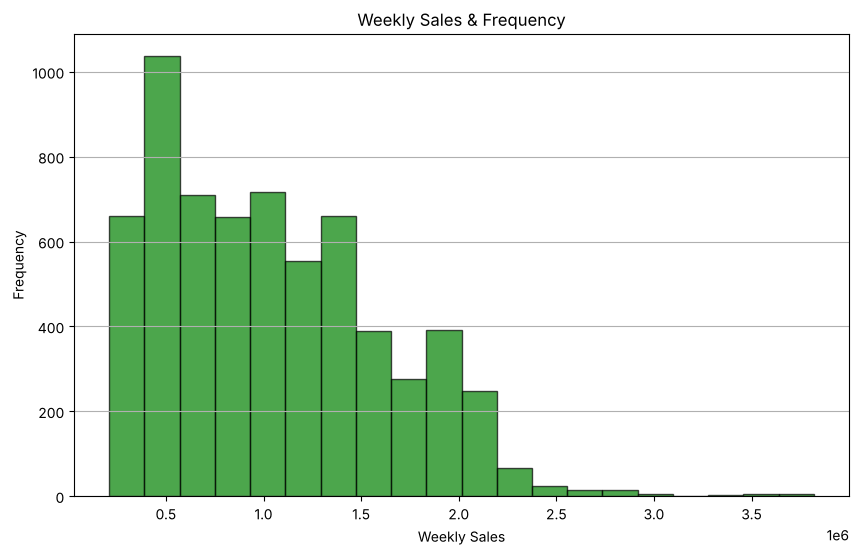

In [3]:
# plt.plot(x,y)
# plt.scatter(x,y)
# plt.bar(x,y)
# plt.pie(x,labels=y,autopct='%1.1f%%,startangle=90)
# plt.hist(x, bins=5)

# CHART 1: Histogram  (was: RAM & Frequency)
plt.figure(figsize=(10,6))
plt.hist(df["Weekly_Sales"], bins=20, color="Green",alpha=0.7,edgecolor="Black")
plt.title("Weekly Sales & Frequency")
plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")
plt.grid(axis="y")
xmin, xmax = plt.xlim()
print("The chart currently goes from", xmin, "to", xmax)
ymin, ymax = plt.ylim()
print("The chart currently goes from", ymin, "to", ymax)
plt.savefig("Weekly Sales & Frequency Diagram.png")
plt.show()

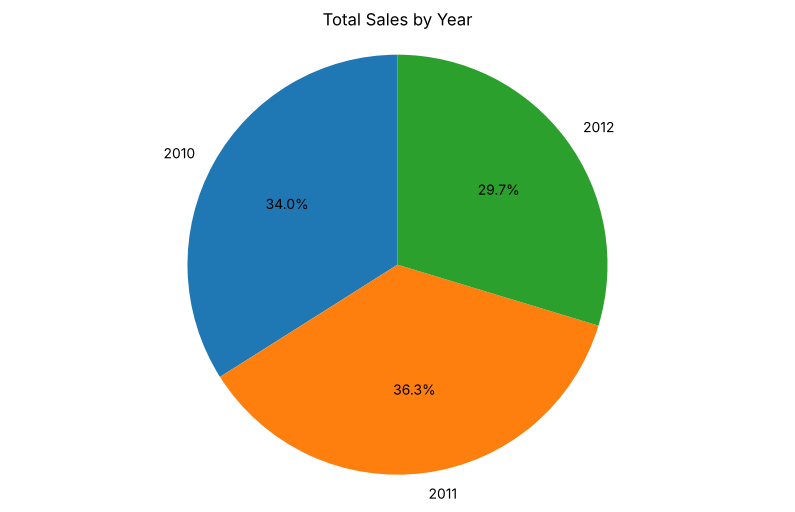

In [4]:
# CHART 2: Pie chart  (was: Quantity Sold by Brand)
year_sales=df.groupby("Year")["Weekly_Sales"].sum()

plt.figure(figsize=(10,6))
plt.pie(year_sales, labels=year_sales.index, autopct='%1.1f%%', startangle=90)
plt.title("Total Sales by Year")
plt.axis("equal")
plt.savefig("Total Sales by Year.png")
plt.show()

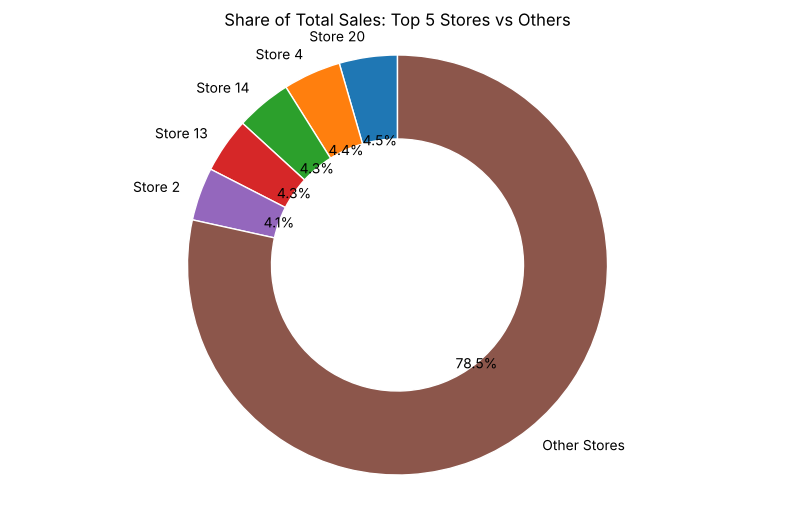

In [5]:
# CHART 3: Donut chart  (same plt.pie function + a hole using wedgeprops)
store_sales=df.groupby("Store")["Weekly_Sales"].sum().sort_values(ascending=False)
top5=store_sales.head(5)
top5["Other Stores"]=store_sales.iloc[5:].sum()

plt.figure(figsize=(10,6))
plt.pie(top5, labels=[f"Store {s}" if s!="Other Stores" else s for s in top5.index],
        autopct='%1.1f%%', startangle=90, wedgeprops={"width":0.4, "edgecolor":"white"})
plt.title("Share of Total Sales: Top 5 Stores vs Others")
plt.axis("equal")
plt.savefig("Top 5 Stores Donut.png")
plt.show()